Do you want to use custom input? (yes/no):  no



--- Intersections ---
ID: A | Name: North Station
ID: B | Name: Central Square
ID: C | Name: South Gate
ID: D | Name: East Boulevard

--- Roads ---
ID: R1 | A -> B | Dist: 5.0km | Max Speed: 50km/h | Current Speed: 45km/h
ID: R2 | B -> C | Dist: 10.0km | Max Speed: 60km/h | Current Speed: 15km/h
ID: R3 | A -> D | Dist: 7.0km | Max Speed: 50km/h | Current Speed: 48km/h
ID: R4 | D -> C | Dist: 6.0km | Max Speed: 40km/h | Current Speed: 38km/h

--- Route Planning & Traffic Impact Comparison ---


Enter Source Intersection ID:  R1
Enter Destination Intersection ID:  R3



[Executing Dijkstra's Algorithm]
  Ideal (Free Flow) Route : None | Travel Time: inf hours
  Congested (Real-Time) Route: None | Travel Time: inf hours

[Executing Bellman-Ford Algorithm]
  Ideal (Free Flow) Route : None | Travel Time: inf hours
  Congested (Real-Time) Route: None | Travel Time: inf hours

--- Traffic Congestion Analysis ---
Road R1 (A->B): Speed Ratio: 0.90 | Status: Free Flow
Road R2 (B->C): Speed Ratio: 0.25 | Status: Heavy Congestion
Road R3 (A->D): Speed Ratio: 0.96 | Status: Free Flow
Road R4 (D->C): Speed Ratio: 0.95 | Status: Free Flow

Is network fully reachable from every position? False


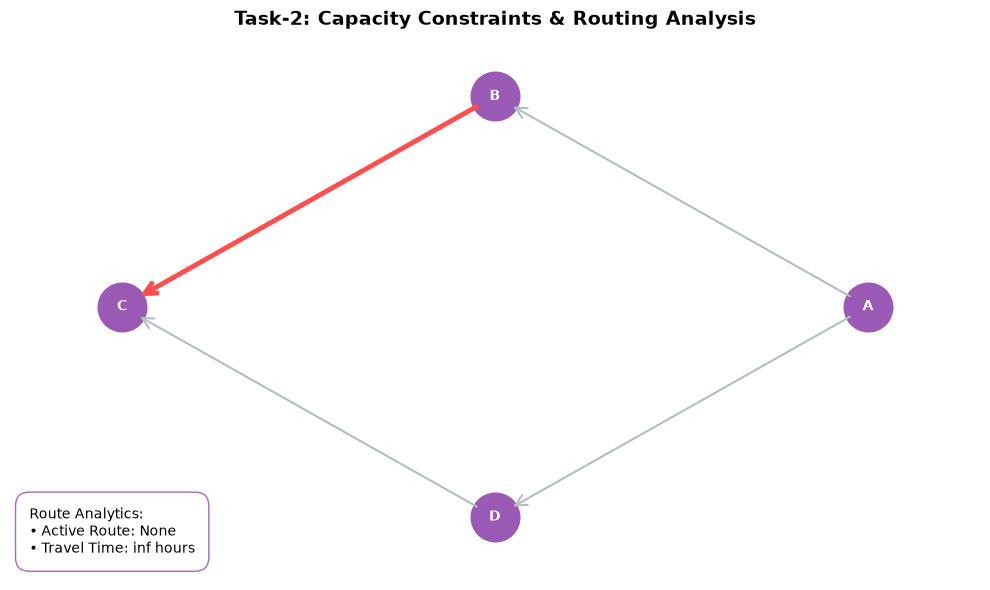

In [3]:
import heapq
import json
import matplotlib.pyplot as plt

class TrafficManagementSystem:
    def __init__(self):
        self.intersections = {}
        self.roads = {}

    def add_intersection(self, id, name):
        self.intersections[id] = {"name": name, "neighbors": []}

    def add_road(self, id, start, end, distance, max_speed, current_speed):
        self.roads[id] = {
            "start": start,
            "end": end,
            "distance": distance,
            "max_speed": max_speed,
            "current_speed": current_speed
        }
        if start in self.intersections:
            self.intersections[start]["neighbors"].append(id)

    def save_network(self, filename):
        data = {"intersections": self.intersections, "roads": self.roads}
        with open(filename, 'w') as f:
            json.dump(data, f)

    def load_network(self, filename):
        with open(filename, 'r') as f:
            data = json.load(f)
            self.intersections = data["intersections"]
            self.roads = data["roads"]

    def display_network(self):
        print("\n--- Intersections ---")
        for node_id, node_info in self.intersections.items():
            print(f"ID: {node_id} | Name: {node_info['name']}")
        print("\n--- Roads ---")
        for road_id, road_info in self.roads.items():
            print(f"ID: {road_id} | {road_info['start']} -> {road_info['end']} | Dist: {road_info['distance']}km | Max Speed: {road_info['max_speed']}km/h | Current Speed: {road_info['current_speed']}km/h")

    def compute_route_dijkstra(self, source, destination, use_congestion=True):
        if source not in self.intersections or destination not in self.intersections:
            return None, float('inf')

        pq = [(0, source, [])]
        visited = set()

        while pq:
            cost, current, path = heapq.heappop(pq)

            if current in visited:
                continue
            visited.add(current)

            if current == destination:
                return path + [current], cost

            for road_id in self.intersections.get(current, {}).get("neighbors", []):
                road = self.roads[road_id]
                neighbor = road["end"]
                
                if neighbor in visited:
                    continue
                
                speed = road["current_speed"] if use_congestion else road["max_speed"]
                if speed <= 0:
                    continue 
                edge_cost = road["distance"] / speed

                heapq.heappush(pq, (cost + edge_cost, neighbor, path + [current]))

        return None, float('inf')

    def compute_route_bellman_ford(self, source, destination, use_congestion=True):
        if source not in self.intersections or destination not in self.intersections:
            return None, float('inf')
        
        distances = {node: float('inf') for node in self.intersections}
        predecessors = {node: None for node in self.intersections}
        distances[source] = 0
        
        for _ in range(len(self.intersections) - 1):
            for road in self.roads.values():
                u, v = road["start"], road["end"]
                speed = road["current_speed"] if use_congestion else road["max_speed"]
                if speed <= 0:
                    continue
                weight = road["distance"] / speed
                
                if distances[u] != float('inf') and distances[u] + weight < distances[v]:
                    distances[v] = distances[u] + weight
                    predecessors[v] = u

        if distances[destination] == float('inf'):
            return None, float('inf')
            
        path = []
        curr = destination
        while curr is not None:
            path.append(curr)
            curr = predecessors[curr]
        path.reverse()
        
        return path, distances[destination]

    def analyze_traffic(self):
        print("\n--- Traffic Congestion Analysis ---")
        for road_id, road in self.roads.items():
            ratio = road["current_speed"] / road["max_speed"] if road["max_speed"] > 0 else 0
            if ratio <= 0.3:
                status = "Heavy Congestion"
            elif ratio <= 0.7:
                status = "Moderate Traffic"
            else:
                status = "Free Flow"
            print(f"Road {road_id} ({road['start']}->{road['end']}): Speed Ratio: {ratio:.2f} | Status: {status}")

    def check_network_connectivity(self):
        if not self.intersections:
            return True
        
        def get_reachable_count(start_node):
            visited = set()
            queue = [start_node]
            while queue:
                current = queue.pop(0)
                if current not in visited:
                    visited.add(current)
                    for road_id in self.intersections.get(current, {}).get("neighbors", []):
                        neighbor = self.roads[road_id]["end"]
                        if neighbor not in visited:
                            queue.append(neighbor)
            return len(visited)

        total_nodes = len(self.intersections)
        for node in self.intersections:
            if get_reachable_count(node) != total_nodes:
                return False
        return True

    def visualize_capacity_flow(self, active_path, travel_time):
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.set_title("Task-2: Capacity Constraints & Routing Analysis", fontsize=14, fontweight='bold')
        
        nodes = list(self.intersections.keys())
        num_nodes = len(nodes)
        
        import math
        pos = {}
        for idx, node in enumerate(nodes):
            angle = 2 * math.pi * idx / num_nodes
            pos[node] = (math.cos(angle), math.sin(angle))
            
        for road_id, road in self.roads.items():
            u, v = road["start"], road["end"]
            if u not in pos or v not in pos:
                continue
            x1, y1 = pos[u]
            x2, y2 = pos[v]
            
            is_on_path = False
            if active_path:
                for i in range(len(active_path) - 1):
                    if active_path[i] == u and active_path[i+1] == v:
                        is_on_path = True
                        break
                        
            ratio = road["current_speed"] / road["max_speed"] if road["max_speed"] > 0 else 0
            
            if is_on_path:
                ecolor = '#2ecc71'
                ewidth = 4.5
            else:
                if ratio <= 0.3:
                    ecolor = '#ff4d4d'
                    ewidth = 3.5
                elif ratio <= 0.7:
                    ecolor = '#e67e22'
                    ewidth = 2.5
                else:
                    ecolor = '#b2bec3'
                    ewidth = 1.5
                    
            ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                        arrowprops=dict(arrowstyle="->", color=ecolor, lw=ewidth, mutation_scale=20, shrinkA=15, shrinkB=15))
            
        for node, (x, y) in pos.items():
            ax.plot(x, y, marker='o', markersize=35, color='#9b59b6', linestyle='None')
            ax.text(x, y, str(node), color='white', ha='center', va='center', fontweight='bold', fontsize=10)
            
        path_string = " -> ".join(active_path) if active_path else "None"
        info_text = f"Route Analytics:\n• Active Route: {path_string}\n• Travel Time: {travel_time:.2f} hours"
        ax.text(0.02, 0.05, info_text, transform=ax.transAxes, 
                bbox=dict(facecolor='white', alpha=0.9, edgecolor='#9b59b6', boxstyle='round,pad=1'))
        
        ax.set_xlim(-1.3, 1.3)
        ax.set_ylim(-1.3, 1.3)
        ax.axis('off')
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    tms = TrafficManagementSystem()
    
    choice = input("Do you want to use custom input? (yes/no): ").strip().lower()
    
    if choice in ['yes', 'y']:
        num_intersections = int(input("Enter number of intersections: "))
        for _ in range(num_intersections):
            node_id = input("Intersection ID: ").strip()
            name = input("Intersection Name: ").strip()
            tms.add_intersection(node_id, name)
            
        num_roads = int(input("Enter number of roads: "))
        for _ in range(num_roads):
            road_id = input("Road ID: ").strip()
            start = input("Start Intersection ID: ").strip()
            end = input("End Intersection ID: ").strip()
            distance = float(input("Distance (km): "))
            max_speed = float(input("Max Speed (km/h): "))
            current_speed = float(input("Current Speed (km/h): "))
            tms.add_road(road_id, start, end, distance, max_speed, current_speed)
    else:
        tms.add_intersection("A", "North Station")
        tms.add_intersection("B", "Central Square")
        tms.add_intersection("C", "South Gate")
        tms.add_intersection("D", "East Boulevard")
        
        tms.add_road("R1", "A", "B", 5.0, 50, 45)
        tms.add_road("R2", "B", "C", 10.0, 60, 15)
        tms.add_road("R3", "A", "D", 7.0, 50, 48)
        tms.add_road("R4", "D", "C", 6.0, 40, 38)
    
    tms.display_network()
    
    print("\n--- Route Planning & Traffic Impact Comparison ---")
    src = input("Enter Source Intersection ID: ").strip()
    dest = input("Enter Destination Intersection ID: ").strip()
    
    print("\n[Executing Dijkstra's Algorithm]")
    p_dij_free, t_dij_free = tms.compute_route_dijkstra(src, dest, use_congestion=False)
    p_dij_cong, t_dij_cong = tms.compute_route_dijkstra(src, dest, use_congestion=True)
    print(f"  Ideal (Free Flow) Route : {p_dij_free} | Travel Time: {t_dij_free:.2f} hours")
    print(f"  Congested (Real-Time) Route: {p_dij_cong} | Travel Time: {t_dij_cong:.2f} hours")
    
    print("\n[Executing Bellman-Ford Algorithm]")
    p_bf_free, t_bf_free = tms.compute_route_bellman_ford(src, dest, use_congestion=False)
    p_bf_cong, t_bf_cong = tms.compute_route_bellman_ford(src, dest, use_congestion=True)
    print(f"  Ideal (Free Flow) Route : {p_bf_free} | Travel Time: {t_bf_free:.2f} hours")
    print(f"  Congested (Real-Time) Route: {p_bf_cong} | Travel Time: {t_bf_cong:.2f} hours")
    tms.analyze_traffic()
    print(f"\nIs network fully reachable from every position? {tms.check_network_connectivity()}")
    tms.visualize_capacity_flow(p_dij_cong, t_dij_cong)